<a href="https://colab.research.google.com/github/KavinMadusanka/fake-news-detection/blob/feat%2Fevaluation/notebooks/Model_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!git config --global user.email "piyushaprabhasari@gmail.com"
!git config --global user.name "Prabhasari"

In [2]:
REPO = "fake-news-detection"
OWNER = "KavinMadusanka"       # repo owner’s username (yours)
TOKEN = "Token"

!git clone https://{TOKEN}@github.com/{OWNER}/{REPO}.git
%cd /content/{REPO}


Cloning into 'fake-news-detection'...
remote: Enumerating objects: 80, done.
remote: Counting objects: 100% (80/80), done.
remote: Compressing objects: 100% (73/73), done.
remote: Total 80 (delta 39), reused 23 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (80/80), 2.02 MiB | 10.10 MiB/s, done.
Resolving deltas: 100% (39/39), done.
/content/fake-news-detection


In [3]:
BRANCH = "feat/evaluation"
!git checkout -b {BRANCH}

Switched to a new branch 'feat/evaluation'


In [6]:
#  Install gdown (only needed once)
!pip install -q gdown

#  Download all models from your shared Google Drive folder
# (this will create a 'results/models' directory automatically)
!gdown --folder "https://drive.google.com/drive/folders/1HueLA-lxnpy1wLU3DyB5SdwmLH1bDtro?usp=sharing" -O results/models

#  Verify that files were downloaded correctly
!ls -lh results/models

print("All models successfully downloaded into results/models/")

Retrieving folder contents
Retrieving folder 15ItQcU2AyavAqT94X0DzGDeDfCr_RUe7 models
Processing file 1eF8mo5J2TD957yQ3SiDLC8zdCXUjpYBo logreg.joblib
Processing file 1Omfc_7N2s7iExZJoYg4TNhwvW57Kf87R lstm_tokenizer.joblib
Processing file 1rGWU7Ij5b4rC3CkZGAhWe8wjXJKVlOyc lstm.h5
Processing file 1WXg-VKbjyUwedXhJfQPRuHCVNwgox8SP lstm.keras
Processing file 1lUNtFkFEsr6t-iol2aTV2MMLa7CUafAH svm.joblib
Processing file 1HOxoEmJw9vshUn7s1zsJW-0Pqa7rw71Q tfidf_logreg.joblib
Processing file 1S5FeCo24lIG3VZgFib9oWoaYF34L7L5B tfidf_vectorizer.joblib
Processing file 1EwX4E5G4mzKgxUSiRnpJd9eyw-oT8UzW tfidf.joblib
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1eF8mo5J2TD957yQ3SiDLC8zdCXUjpYBo
To: /content/fake-news-detection/results/models/models/logreg.joblib
100% 161k/161k [00:00<00:00, 77.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Omfc_7N2s7iExZJoYg4TNhwvW57Kf87R
To: /c

In [7]:
import os, re, joblib, numpy as np, tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences

MODEL_DIR = "results/models/models"   # <— shared-link download location
MAX_LEN = 300                  # must match training

# --- 0) Show what we have ---
print("📁 Available files in results/models:", os.listdir(MODEL_DIR))

# --- 1) Cleaner ---
def clean_text(t: str) -> str:
    t = t.lower()
    t = re.sub(r"http\S+", "", t)
    t = re.sub(r"[^a-z\s]", "", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

# --- 2) Safe loaders (load only if present) ---
def safe_joblib(name):
    path = os.path.join(MODEL_DIR, name)
    return joblib.load(path) if os.path.exists(path) else None

def safe_load_lstm():
    if os.path.exists(os.path.join(MODEL_DIR, "lstm.keras")):
        return tf.keras.models.load_model(os.path.join(MODEL_DIR, "lstm.keras"))
    if os.path.exists(os.path.join(MODEL_DIR, "lstm.h5")):
        return tf.keras.models.load_model(os.path.join(MODEL_DIR, "lstm.h5"))
    return None

# Classical models / vectorizers
lr_model         = safe_joblib("logreg.joblib")
svm_model        = safe_joblib("svm.joblib")
tfidf_vectorizer = safe_joblib("tfidf_vectorizer.joblib")
tfidf_logreg     = safe_joblib("tfidf_logreg.joblib")

# LSTM & tokenizer
lstm_model      = safe_load_lstm()
lstm_tokenizer  = safe_joblib("lstm_tokenizer.joblib")

print("\n✅ Loaded objects:")
for label, obj in [
    ("LR", lr_model), ("SVM", svm_model),
    ("TFIDF Vectorizer", tfidf_vectorizer), ("TFIDF+LogReg", tfidf_logreg),
    ("LSTM", lstm_model), ("LSTM Tokenizer", lstm_tokenizer)
]:
    print(f" - {label}: {'OK' if obj is not None else 'missing'}")

📁 Available files in results/models: ['logreg.joblib', 'lstm.h5', 'tfidf_vectorizer.joblib', 'lstm_tokenizer.joblib', 'tfidf.joblib', 'tfidf_logreg.joblib', 'svm.joblib', 'lstm.keras']


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 8 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



✅ Loaded objects:
 - LR: OK
 - SVM: OK
 - TFIDF Vectorizer: OK
 - TFIDF+LogReg: OK
 - LSTM: OK
 - LSTM Tokenizer: OK


In [8]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

def predict_fake_news(text):
    """
    Predict Fake/Real using:
      1. TF-IDF + Logistic Regression
      2. SVM
      3. LSTM
    Returns each result and a majority-vote decision.
    """
    results = {}
    text_cleaned = clean_text(text)

    # --- 1. TF-IDF + Logistic Regression ---
    X_tfidf = tfidf_vectorizer.transform([text_cleaned])
    pred_tfidf = tfidf_logreg.predict(X_tfidf)[0]
    prob_tfidf = tfidf_logreg.predict_proba(X_tfidf)[0][pred_tfidf]
    results['TFIDF_LogReg'] = ('Fake' if pred_tfidf else 'Real', round(prob_tfidf, 3))

    # --- 2. SVM ---
    pred_svm = svm_model.predict(X_tfidf)[0]
    score = svm_model.decision_function(X_tfidf)[0]
    svm_conf = float(1 / (1 + np.exp(-abs(score))))   # pseudo-confidence
    results['SVM'] = ('Fake' if pred_svm else 'Real', round(svm_conf, 3))

    # --- 3. LSTM ---
    seq = lstm_tokenizer.texts_to_sequences([text_cleaned])
    pad = pad_sequences(seq, maxlen=300)
    prob_fake = float(lstm_model.predict(pad, verbose=0)[0][0])
    pred_lstm = 1 if prob_fake >= 0.5 else 0
    results['LSTM'] = ('Fake' if pred_lstm else 'Real', round(prob_fake, 3))

    # --- Majority Vote ---
    votes = [label for label, _ in results.values()]
    final = 'Fake' if votes.count('Fake') >= 2 else 'Real'
    results['Majority_Vote'] = (final, None)

    return results

In [9]:
news_text = input("Enter a news headline or paragraph:\n")
preds = predict_fake_news(news_text)

print("\n🧾 Prediction Results:")
for model, (label, prob) in preds.items():
    print(f"{model:15s}: {label}  (Confidence: {prob})")


Enter a news headline or paragraph:
Scientists discover an ancient alien city hidden under the Sahara desert.

🧾 Prediction Results:
TFIDF_LogReg   : Fake  (Confidence: 0.729)
SVM            : Fake  (Confidence: 0.61)
LSTM           : Fake  (Confidence: 0.914)
Majority_Vote  : Fake  (Confidence: None)


In [10]:
news_text = input("Enter a news headline or paragraph:\n")
preds = predict_fake_news(news_text)

print("\n🧾 Prediction Results:")
for model, (label, prob) in preds.items():
    print(f"{model}: {label} (Confidence: {prob})")

Enter a news headline or paragraph:
Sri Lanka Central Bank introduces new digital payment regulations for 2025.

🧾 Prediction Results:
TFIDF_LogReg: Real (Confidence: 0.599)
SVM: Fake (Confidence: 0.599)
LSTM: Fake (Confidence: 0.88)
Majority_Vote: Fake (Confidence: None)


          Model  Accuracy        F1
0            LR  0.990421  0.990798
1           SVM  0.997550  0.997656
2          LSTM  0.972600  0.973150
3  TFIDF_LogReg  0.990867  0.991234


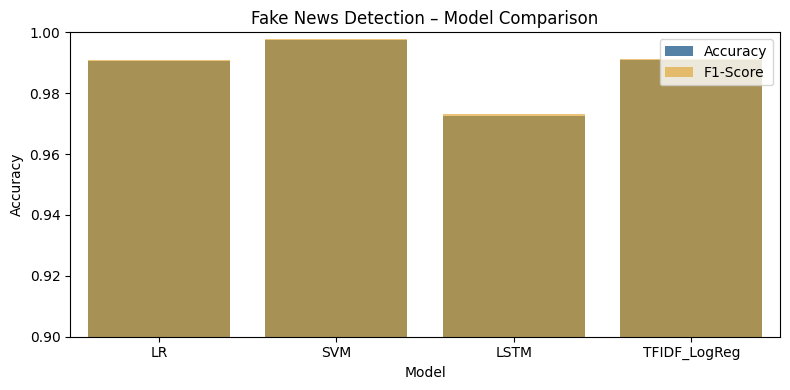

In [11]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv('results/model_metrics.csv')
print(df)

plt.figure(figsize=(8,4))
sns.barplot(x='Model', y='Accuracy', data=df, color='steelblue', label='Accuracy')
sns.barplot(x='Model', y='F1', data=df, color='orange', alpha=0.6, label='F1-Score')
plt.title('Fake News Detection – Model Comparison')
plt.ylim(0.9,1.0)
plt.legend()
plt.tight_layout()
plt.show()

In [34]:
!pip -q install streamlit==1.37.0 pyngrok==7.1.6
from google.colab import drive
drive.mount('/content/drive')

MODEL_DIR = "/content/drive/MyDrive/fake_news_project/results/models/models"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [39]:
%%writefile app.py

import streamlit as st
st.set_page_config(page_title="Fake News Detection", page_icon="📰")

import re, joblib, numpy as np, tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences

# --------- CONFIG ----------
MODEL_DIR = "results/models/models"
MAX_LEN = 300
USE_LSTM = True     # set to False if you want only TF-IDF + SVM
# ---------------------------

# ---------- TEXT CLEANER ----------
def clean_text(t):
    t = t.lower()
    t = re.sub(r"http\S+", "", t)
    t = re.sub(r"[^a-z\s]", "", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

# ---------- LOAD MODELS ----------
@st.cache_resource
def load_models():
    tfidf = joblib.load(f"{MODEL_DIR}/tfidf_vectorizer.joblib")
    tfidf_lr = joblib.load(f"{MODEL_DIR}/tfidf_logreg.joblib")
    svm = joblib.load(f"{MODEL_DIR}/svm.joblib")

    lstm, tokenizer = None, None
    if USE_LSTM:
        lstm = tf.keras.models.load_model(f"{MODEL_DIR}/lstm.h5", compile=False)
        try:
            tokenizer = joblib.load(f"{MODEL_DIR}/lstm_tokenizer.joblib")
        except:
            tokenizer = None
            st.warning("Tokenizer for LSTM not found — skipping LSTM model.")
    return tfidf, tfidf_lr, svm, lstm, tokenizer


tfidf, tfidf_lr, svm, lstm, tokenizer = load_models()

# ---------- PAGE HEADER ----------
st.title("📰 Fake News Detection Dashboard")
st.markdown(
    "This tool analyzes a given news headline or short paragraph "
    "using multiple machine-learning models to determine whether it’s **real or fake news**."
)

user_text = st.text_area(
    "Enter a news headline or paragraph:",
    height=160,
    placeholder="e.g. Sri Lanka central bank announces new monetary policy adjustments for 2025"
)
run = st.button("🔍 Detect")

# ---------- HELPER ----------
def pseudo_confidence_from_decision(score: float) -> float:
    """Normalize SVM decision score to 0–1."""
    return float(1 / (1 + np.exp(-abs(score))))

# ---------- PREDICTION ----------
if run and user_text.strip():
    text_c = clean_text(user_text)
    results = []

    # --- TF-IDF + Logistic Regression ---
    X = tfidf.transform([text_c])
    pred_lr = int(tfidf_lr.predict(X)[0])
    prob_lr = float(tfidf_lr.predict_proba(X)[0][pred_lr])
    label_lr = "Fake" if pred_lr == 1 else "Real"
    results.append(("TFIDF + LogReg", label_lr, prob_lr))

    # --- SVM ---
    pred_svm = int(svm.predict(X)[0])
    score = float(svm.decision_function(X)[0])
    conf_svm = pseudo_confidence_from_decision(score)
    label_svm = "Fake" if pred_svm == 1 else "Real"
    results.append(("SVM", label_svm, conf_svm))

    # --- LSTM ---
    if USE_LSTM and tokenizer is not None and lstm is not None:
        seq = tokenizer.texts_to_sequences([text_c])
        pad = pad_sequences(seq, maxlen=MAX_LEN)
        prob_fake = float(lstm.predict(pad, verbose=0)[0][0])
        pred_lstm = 1 if prob_fake >= 0.5 else 0
        label_lstm = "Fake" if pred_lstm == 1 else "Real"
        results.append(("LSTM", label_lstm, prob_fake))

    # --- Majority Vote ---
    votes = [r[1] for r in results]
    final_label = "Fake" if votes.count("Fake") >= (len(votes)//2 + 1) else "Real"

    # ---------- DISPLAY RESULTS ----------
    st.subheader("Prediction Results")
    for name, label, conf in results:
        st.write(f"**{name}:** {label}  |  Confidence = `{conf:.3f}`")

    st.markdown("---")
    if final_label == "Fake":
        st.error(f"🧾 **Final Decision:** {final_label}")
    else:
        st.success(f"🧾 **Final Decision:** {final_label}")

    st.caption("*(Note: SVM confidence is a normalized margin, not a true probability.)*")

else:
    st.info("💡 Enter text above and click **Detect** to begin.")


Overwriting app.py


In [40]:
import os
os.environ["NGROK_API_KEY"] = "33sdEyTq9jF06Inp5UiZPbz2j4C_6kXyCb3f2Yy1Dp48hffih"


In [41]:
!pip -q install pyngrok==7.1.6

from pyngrok import ngrok
import subprocess, time, os

# If you have an ngrok API key, set it once; otherwise comment the next 2 lines.
NGROK_API_KEY = os.getenv("NGROK_API_KEY", None)
if not NGROK_API_KEY:
    print("If you have an ngrok API key, set it like this before running:")
    print("import os; os.environ['NGROK_API_KEY'] = 'YOUR_KEY_HERE'")

# Kill any previous tunnels
ngrok.kill()

# Start Streamlit
port = 8501
proc = subprocess.Popen(["streamlit", "run", "app.py",
                         "--server.port", str(port),
                         "--server.address", "0.0.0.0"])

# Give it a moment to boot
time.sleep(5)

# Open tunnel
if NGROK_API_KEY:
    ngrok.set_auth_token(NGROK_API_KEY)
public_url = ngrok.connect(port, "http").public_url
print("🔗 Public URL:", public_url)


🔗 Public URL: https://tierra-unpouting-obliviously.ngrok-free.dev


In [42]:
!git add app.py
!git commit -m "added Streamlit app.py for final deployment"
!git push --set-upstream origin feat/evaluation

[feat/evaluation 7154cd6] Member D – added Streamlit app.py for final deployment
 1 file changed, 1 insertion(+), 1 deletion(-)
Enumerating objects: 5, done.
Counting objects: 100% (5/5), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (3/3), 330 bytes | 330.00 KiB/s, done.
Total 3 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/KavinMadusanka/fake-news-detection.git
   f6fe0c7..7154cd6  feat/evaluation -> feat/evaluation
Branch 'feat/evaluation' set up to track remote branch 'feat/evaluation' from 'origin'.
